# Array Horizontal TDOA Voting

In [1]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq
import matplotlib.cm as cm

import sys
sys.path.append("/Users/kevinbrennan/Desktop/Diploma/Project/Code/HATS_Code")

from HATS_functions import gcc_phat, corr_to_itd

angles = ["0", "45", "90", "315"]
PathToFiles = "../Audio_Files/Real_World_Measurements/Horizontal"

num_mics = 7
angle_increment = 360/num_mics
fs = 48000

recordings = {}

for angle in angles:
    folder = Path(PathToFiles) / str(angle)
    if folder.is_dir():
        recordings[angle] = {
                '0': folder / "Untitled 1-Audio.wav",
                '1': folder / "Untitled 2-Audio.wav",
                '2': folder / "Untitled 3-Audio.wav",
                '3': folder / "Untitled 4-Audio.wav",
                '4': folder / "Untitled 5-Audio.wav",
                '5': folder / "Untitled 6-Audio.wav",
                '6': folder / "Untitled 7-Audio.wav",
                '7': folder / "Untitled 8-Audio.wav"
            }
    else:
        print(f"Missing folder: {folder}")
        
print(angle_increment)
print(gcc_phat)

print(recordings['0'])
print(recordings.items())

51.42857142857143
<function gcc_phat at 0x1184bc360>
{'0': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 1-Audio.wav'), '1': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 2-Audio.wav'), '2': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 3-Audio.wav'), '3': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 4-Audio.wav'), '4': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 5-Audio.wav'), '5': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 6-Audio.wav'), '6': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 7-Audio.wav'), '7': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 8-Audio.wav')}
dict_items([('0', {'0': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 1-Audio.wav'), '1': PosixPath('../Audio_Files/Real_World_Measurements/Horizontal/0/Untitled 2-Audio.wav'), '2': Po

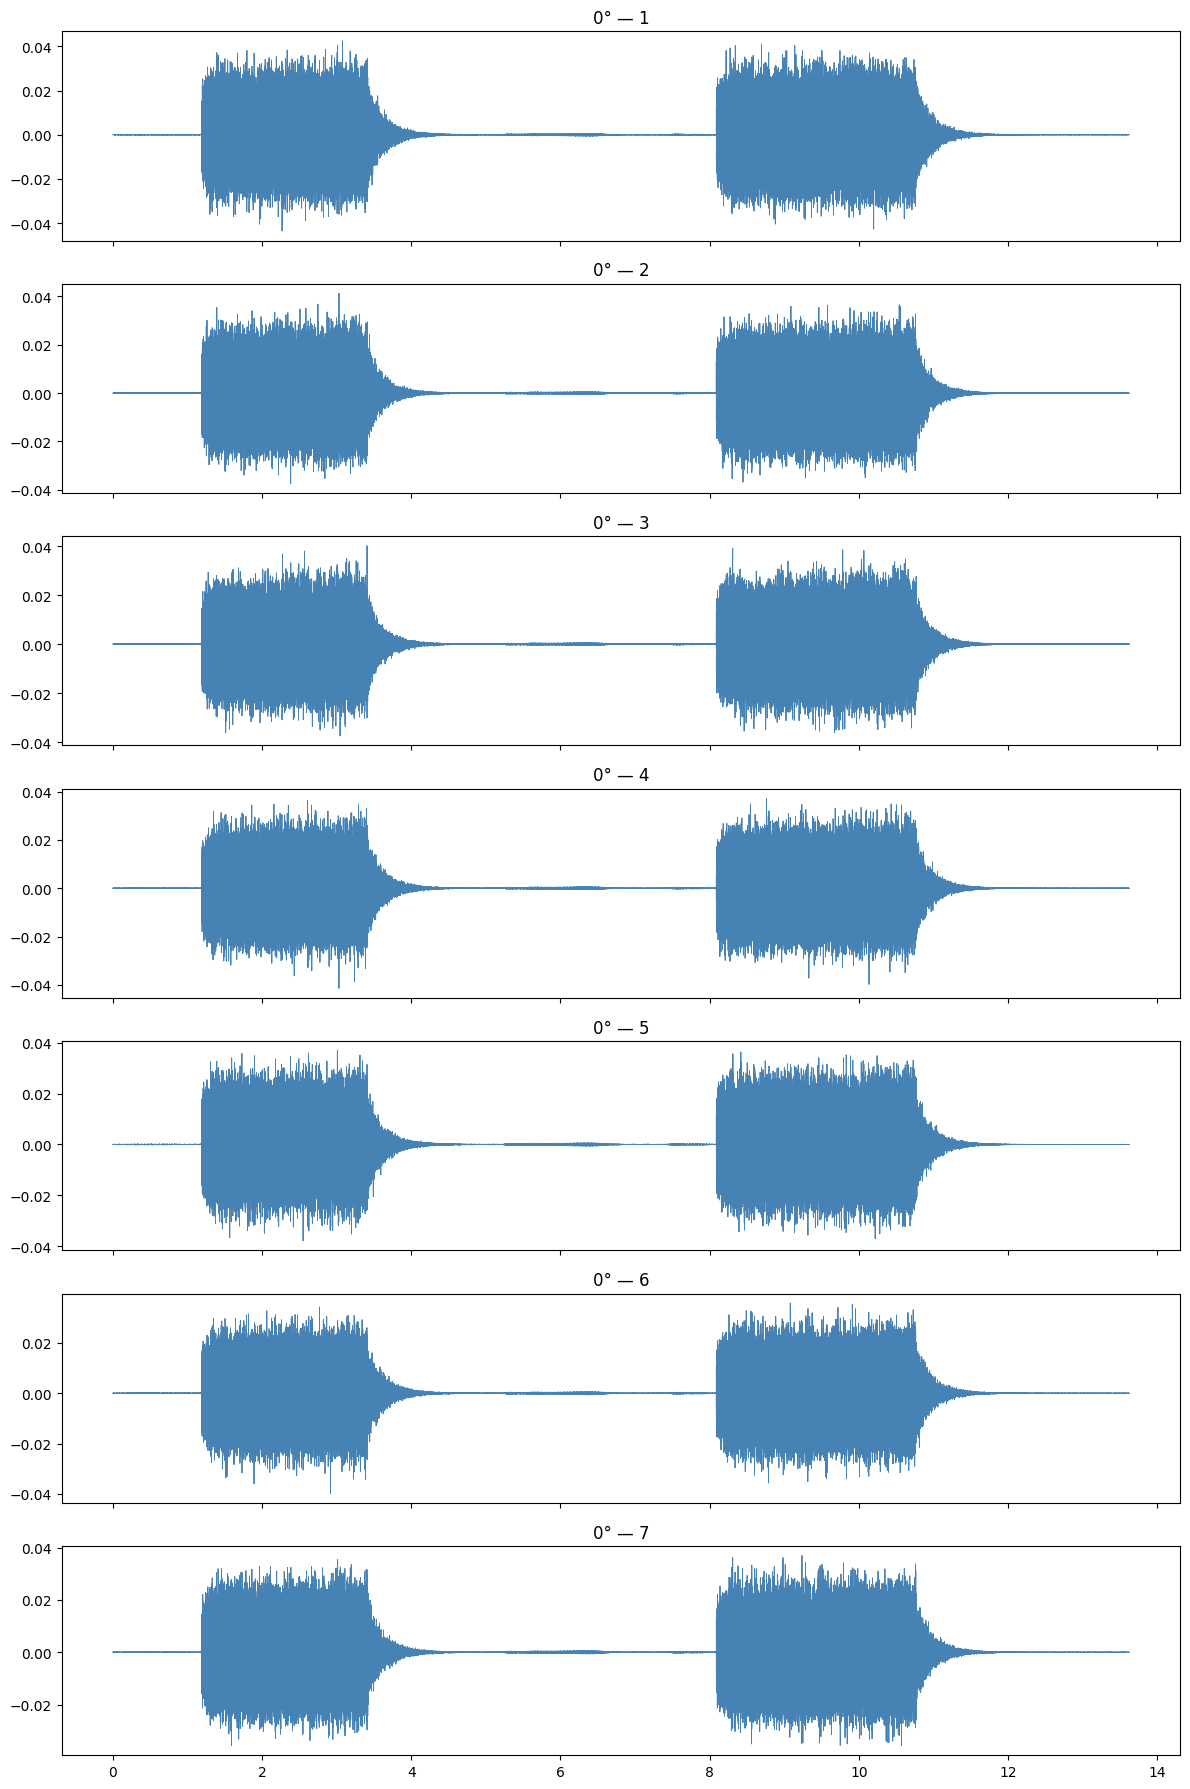

In [2]:
name = '0'
files = recordings[name]

while(True):
    data1, fs = sf.read(files['0'])
    data2, fs = sf.read(files['1'])
    data3, fs = sf.read(files['2'])
    data4, fs = sf.read(files['3'])
    data5, fs = sf.read(files['4'])
    data6, fs = sf.read(files['5'])
    data7, fs = sf.read(files['6'])
    
    fs = fs
    
    t = np.arange(len(data1))/fs
    
    fig, (ax1, ax2, ax3, ax4, ax5, ax6, ax7) = plt.subplots(7, 1, figsize=(12, 18), sharex=True)
    ax1.plot(t, data1, linewidth=0.5, color='steelblue')
    ax2.plot(t, data2, linewidth=0.5, color='steelblue')
    ax3.plot(t, data3, linewidth=0.5, color='steelblue')
    ax4.plot(t, data4, linewidth=0.5, color='steelblue')
    ax5.plot(t, data5, linewidth=0.5, color='steelblue')
    ax6.plot(t, data6, linewidth=0.5, color='steelblue')
    ax7.plot(t, data7, linewidth=0.5, color='steelblue')
    
    ax1.set_title(f'{name}° — 1')
    ax2.set_title(f'{name}° — 2')
    ax3.set_title(f'{name}° — 3')
    ax4.set_title(f'{name}° — 4')
    ax5.set_title(f'{name}° — 5')
    ax6.set_title(f'{name}° — 6')
    ax7.set_title(f'{name}° — 7')

    plt.tight_layout()
    plt.show()
    break 

In [3]:
r = 0.045
x = 2 * r * np.sin(np.radians(30))
y = 2 * r * np.sin(np.radians(60))
z = 2 * r * np.sin(np.radians(90))

dists = [[0, r, r, r, r, r, r],
         [r, 0, x, y, z, y, x],
         [r, x, 0, x, y, z, y],
         [r, y, x, 0, x, y, z],
         [r, z, y, x, 0, x, y],
         [r, y, z, y, x, 0, x],
         [r, x, y, z, y, x, 0],]

scores = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}

magnitude = {'0': 0,
          '1': 0,
          '2': 0,
          '3': 0,
          '4': 0,
          '5': 0,
          '6': 0,}

for i in range(0, 7):
    first = i
    datax, fs = sf.read(recordings['0'][str(i)])
    
    for j in range(i+1, 7):
        second = j
        
        print(i,j)
        
        datay, fs = sf.read(recordings['0'][str(j)])
        
        correlation = gcc_phat(datax, datay)
        itd = corr_to_itd(correlation, dists[i][j], fs)
        
        if(itd < 0):
            scores[str(i)] += 1
        else:
            scores[str(j)] += 1
            
        
print(scores)    
        

0 1
0 2
0 3
0 4
0 5
0 6
1 2
1 3
1 4
1 5
1 6
2 3
2 4
2 5
2 6
3 4
3 5
3 6
4 5
4 6
5 6
{'0': 3, '1': 6, '2': 4, '3': 1, '4': 0, '5': 2, '6': 5}


In [4]:
import matplotlib.cm as cm
mic_angles_deg = [0, 60, 120, 180, 240, 300]
mic_angles_rad = np.radians(mic_angles_deg)
mic_r = 0.045

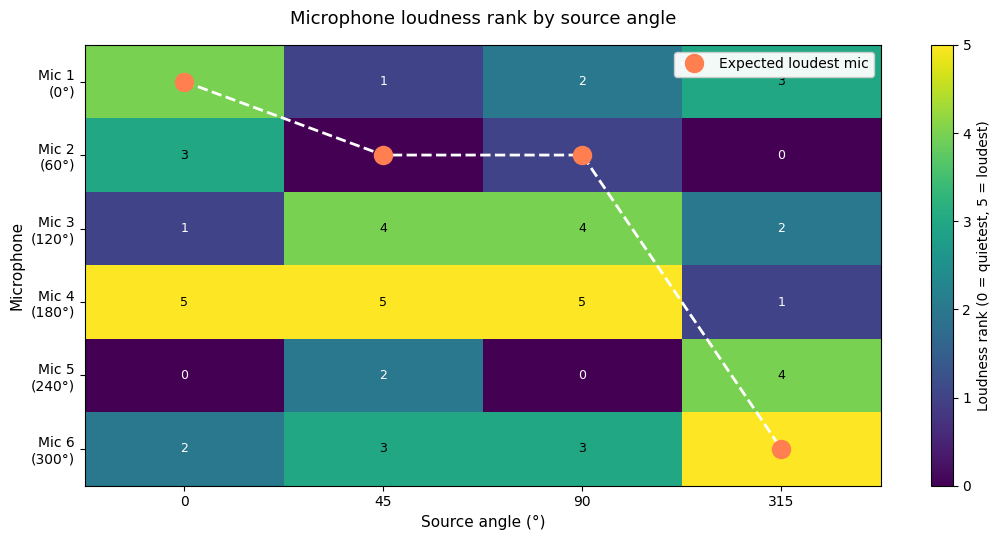

In [5]:
from corrections import mic_onset_position, window_signal
mic_angles_deg = [0, 60, 120, 180, 240, 300]
source_angles = sorted(recordings.keys(), key=lambda x: float(x))
window_length = 48000

magnitude_matrix = np.zeros((6, len(source_angles)))

for j, src_angle in enumerate(source_angles):
    for i in range(1, 7):
        data, fs = sf.read(recordings[src_angle][str(i)])
        
        onset = mic_onset_position(data)
        data_windowed = window_signal(data, onset, window_length)
        
        magnitude_matrix[i-1, j] = np.sqrt(np.mean(data_windowed**2)) #RMS

magnitude_matrix_norm = magnitude_matrix / magnitude_matrix.max(axis=0, keepdims=True)
ranks = np.argsort(np.argsort(magnitude_matrix_norm, axis=0), axis=0)

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(ranks, cmap='viridis', aspect='auto', interpolation='nearest')

# Expected closest mic 
expected_mic_idx = []
for src_angle in source_angles:
    src = float(src_angle) % 360
    diffs = [min(abs(src - m), 360 - abs(src - m)) for m in mic_angles_deg]
    expected_mic_idx.append(np.argmin(diffs))

ax.plot(range(len(source_angles)), expected_mic_idx, 'o--', color='white',
        linewidth=2, markersize=12, markeredgecolor='coral', markeredgewidth=2,
        markerfacecolor='coral', label='Expected loudest mic', zorder=5)

for i in range(6):
    for j in range(len(source_angles)):
        ax.text(j, i, ranks[i, j], ha='center', va='center', 
                color='white' if ranks[i, j] < 3 else 'black', fontsize=9)

ax.set_xticks(range(len(source_angles)))
ax.set_xticklabels(source_angles)
ax.set_yticks(range(6))
ax.set_yticklabels([f'Mic {i+1}\n({mic_angles_deg[i]}°)' for i in range(6)])
ax.set_xlabel('Source angle (°)', fontsize=11)
ax.set_ylabel('Microphone', fontsize=11)
ax.set_title('Microphone loudness rank by source angle', fontsize=13, pad=15)

cbar = fig.colorbar(im, ax=ax, ticks=range(6))
cbar.set_label('Loudness rank (0 = quietest, 5 = loudest)', fontsize=10)

ax.legend(loc='upper right', framealpha=0.95)
ax.grid(False)
plt.tight_layout()
plt.show()

Looks like Reverberant waves all converge on mic 4, at the back of the hall at a higher level than the direct sound wave from the speaker hits microphone 1

In [6]:
print(magnitude_matrix_norm)

[[0.99919403 0.94058992 0.98176081 0.97732501]
 [0.98667049 0.91914266 0.97889493 0.971334  ]
 [0.95469607 0.99858518 0.98804148 0.97510333]
 [1.         1.         1.         0.97313174]
 [0.94452016 0.94937591 0.97396883 0.98663595]
 [0.97728318 0.95872496 0.98586119 1.        ]]


In [7]:
import matplotlib.cm as cm
from pathlib import Path

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


def plot_array_voting(scores, true_source_deg, save_path=None):
    mic_angles_deg = [0, 60, 120, 180, 240, 300]
    mic_angles_rad = np.radians(mic_angles_deg)
    mic_r = 0.045

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={'projection': 'polar'})
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    max_score = max(scores.values())

    # Outer mics
    for i, a in enumerate(mic_angles_rad):
        score = scores[str(i + 1)]
        intensity = score / max_score if max_score > 0 else 0
        size = 200 + 800 * intensity
        color = cm.Blues(0.3 + 0.7 * intensity)

        ax.scatter(a, mic_r, s=size, color=color, zorder=5,
                   edgecolors='steelblue', linewidths=1.5)
        ax.annotate(str(score), (a, mic_r), ha='center', va='center',
                    fontsize=10, fontweight='bold',
                    color='white' if intensity > 0.4 else 'black', zorder=6)
        ax.annotate(f'Mic {i + 1}', (a, mic_r * 1.15), ha='center', fontsize=9)

    # Centre mic
    score_c = scores['0']
    intensity_c = score_c / max_score if max_score > 0 else 0
    size_c = 200 + 800 * intensity_c
    color_c = cm.Blues(0.3 + 0.7 * intensity_c)

    ax.scatter(0, 0, s=size_c, color=color_c, zorder=5,
               edgecolors='steelblue', linewidths=1.5)
    ax.annotate(str(score_c), (0, 0), ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white' if intensity_c > 0.4 else 'black', zorder=6)

    # Winning sector
    outer_scores = {k: v for k, v in scores.items() if k != '0'}
    sorted_mics = sorted(outer_scores.items(), key=lambda x: -x[1])
    winning_mic = int(sorted_mics[0][0])
    second_mic = int(sorted_mics[1][0])

    a1 = mic_angles_deg[winning_mic - 1]
    a2 = mic_angles_deg[second_mic - 1]

    delta = ((a2 - a1 + 180) % 360) - 180

    if delta >= 0:
        sector_start = np.radians(a1)
        sector_end = np.radians(a1 + delta)
    else:
        sector_start = np.radians(a1 + delta)
        sector_end = np.radians(a1)

    theta = np.linspace(sector_start, sector_end, 100)
    ax.fill_between(theta, 0, mic_r, alpha=0.2, color='steelblue',
                label='Estimated sector')

    # Array
    circle_theta = np.linspace(0, 2 * np.pi, 100)
    ax.plot(circle_theta, [mic_r] * 100, color='gray',
            linestyle='--', linewidth=1)

    # True source 
    source_angle_rad = np.radians(true_source_deg)
    source_r = 0.08
    ax.plot([source_angle_rad, source_angle_rad], [0, source_r],
            color='coral', lw=2)
    ax.plot(source_angle_rad, source_r, 'o', color='coral', markersize=10,
            label=f'True source ({true_source_deg}°)')

    ax.set_ylim(0, 0.09)
    ax.set_rticks([])
    ax.set_thetagrids(np.arange(0, 360, 30),
                      labels=[f'{a}°' for a in np.arange(0, 360, 30)])
    ax.set_title(f'DOA — Array TDOA Voting Estimate ({true_source_deg}°)', pad=20)
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()

    if save_path:
        fig.savefig(f"{save_path}.png", dpi=200, bbox_inches='tight')
        fig.savefig(f"{save_path}.pdf", bbox_inches='tight')
    plt.show()
    plt.close(fig)

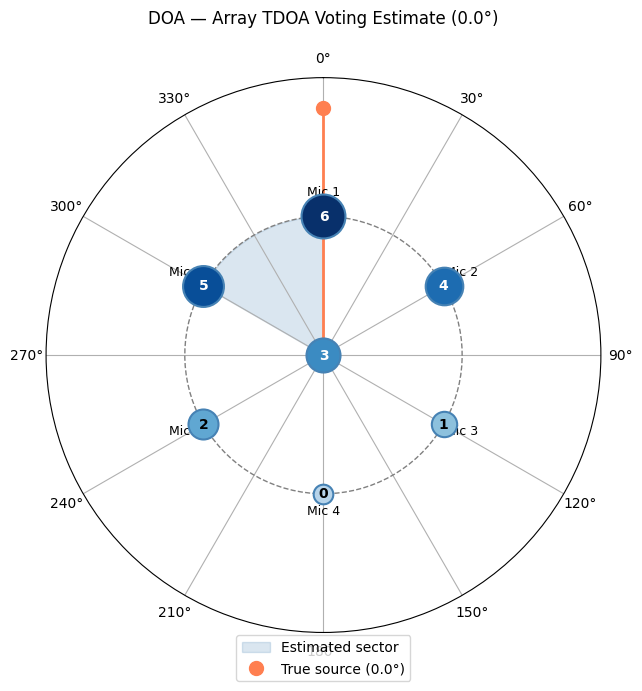

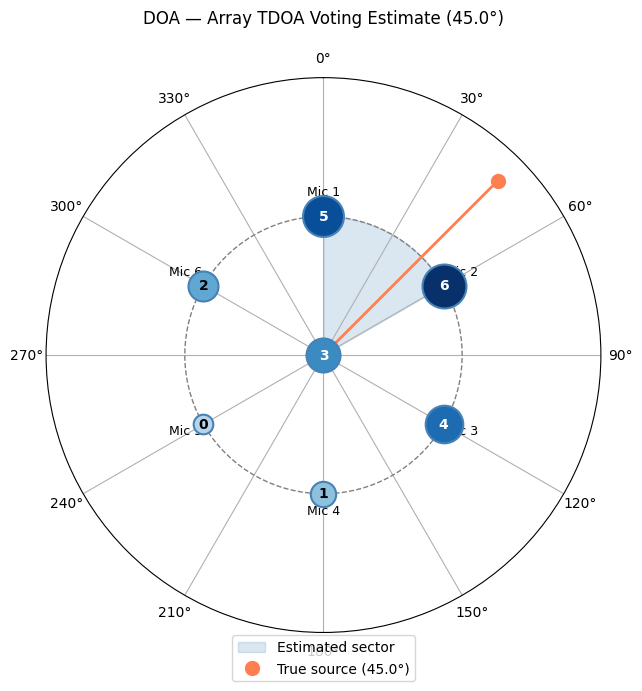

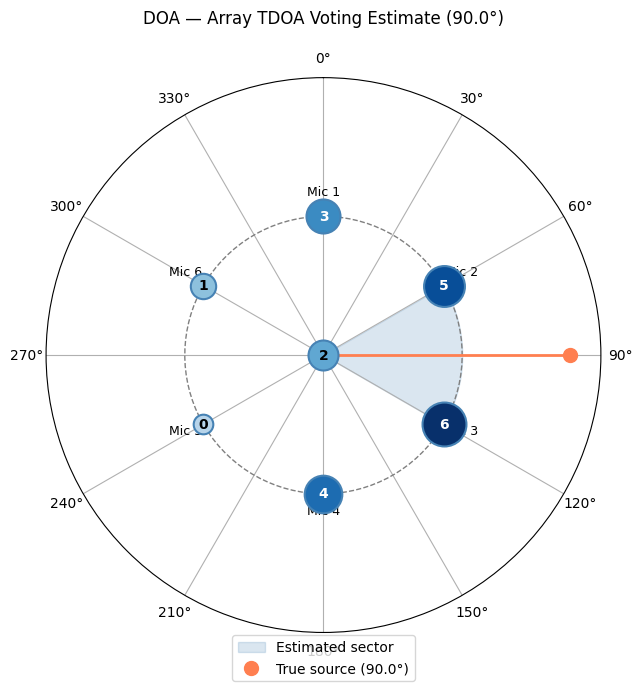

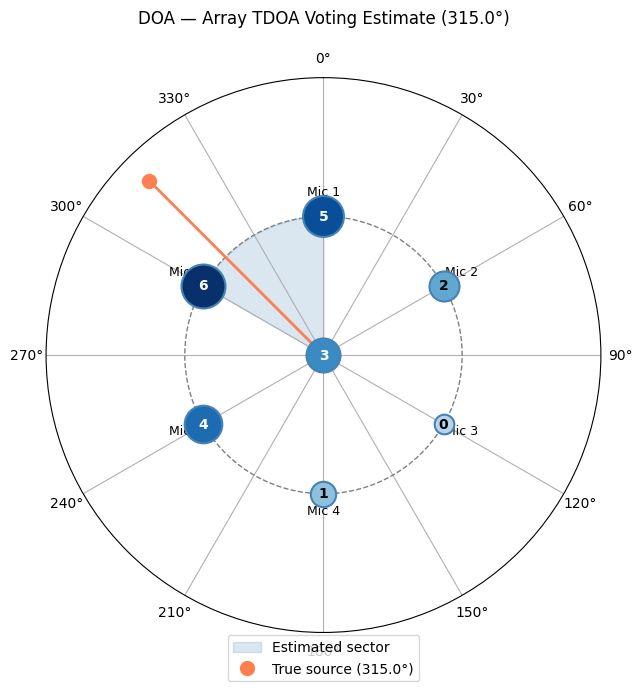

In [8]:
def compute_votes(source_angle_key):
    scores = {str(i): 0 for i in range(7)}
    for i in range(7):
        datax, fs = sf.read(recordings[source_angle_key][str(i)])
        for j in range(i + 1, 7):
            datay, _ = sf.read(recordings[source_angle_key][str(j)])
            correlation = gcc_phat(datax, datay)
            itd = corr_to_itd(correlation, dists[i][j], fs)
            if itd < 0:
                scores[str(i)] += 1
            else:
                scores[str(j)] += 1
    return scores


for source_angle in recordings.keys():
    scores = compute_votes(source_angle)
    plot_array_voting(scores, float(source_angle),
                      figures_dir / f"array_voting_{source_angle}")